# 03 — Pipeline check

*27 Nov 2026.* Sanity checks of the model table built by `windai.data.build` (decisions D1–D12 in
`notes/decisions.md`), for the **val fit**: the power curve is fitted on the train fold (power labels before
1 Apr 2023 local), and the validation fold is only looked at through the raw ensemble, which has no fitted
parameters beyond the curve.

Checks: (1) the fitted curve per zone, (2) the D11 alignment weights as a second test of the timestamp
convention (C9), (3) the RMSE of member 00 against the competition paper's ~280 MW for NO3, (4) bias and
spread of the power ensemble.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from windai.data.build import load_dataset
from windai.data.first_stage import load_nowcast_wind
from windai.data.parks import parks_table, capacity_matrix
from windai.data.dataset_loader import load_power, VALID_ZONES as ZONES

pd.set_option("display.width", 200)
P = [f"p_{m:02d}" for m in range(15)]
df, curve = load_dataset("train", fit="val")
# The test fold is not looked at until the thesis (touched once, F26 §1): keep train and val only
df = df.loc[df["fold"].isin(["train", "val"])].reset_index(drop=True)
print(len(df), "rows;", df.groupby("fold")["issue_time"].nunique().to_dict(), "issues per fold")
curve.summary().round(3)

139292 rows; {'train': 1096, 'val': 355} issues per fold


,a,c,s,d,c_out,s_out,w_prev,w_0,w_next,rmse_cf,n_hours,n_high_wind,cutout_fitted
zone,,,,,,,,,,,,,
ELSPOT NO1,0.758,3.457,1.017,0.0,40.000,1.000,0.373,0.009,0.618,0.161,28394,0,False
ELSPOT NO2,0.877,5.274,1.143,0.0,14.936,0.885,0.241,0.111,0.648,0.092,28406,146,True
ELSPOT NO3,0.852,6.002,1.134,0.0,18.943,1.599,0.217,0.121,0.662,0.088,28406,640,True
ELSPOT NO4,0.731,6.813,1.410,0.0,22.054,3.351,0.218,0.191,0.591,0.097,28406,1034,True


## 1. Fitted curve per zone
The curve f is fitted per park and aggregated, so it isn't exactly the zone's curve. As a visual check it is
drawn against the binned zone CF over capacity-weighted Nowcast wind (train period).

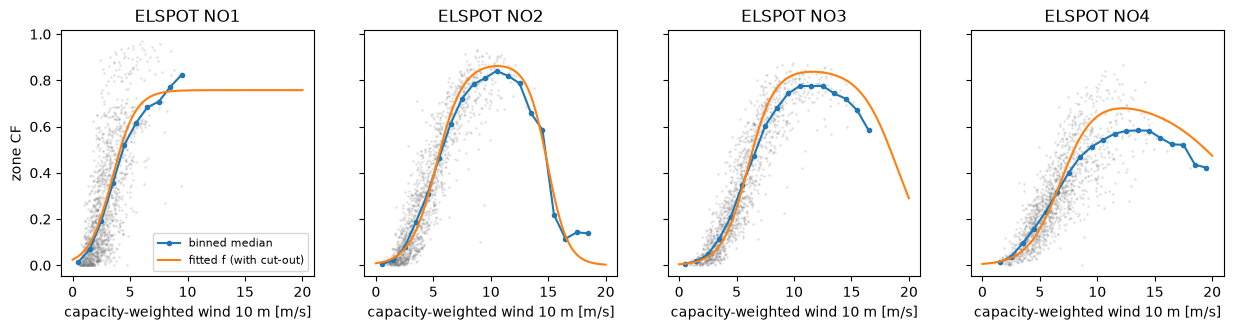

In [2]:
wind = load_nowcast_wind()
wind = wind.loc[wind.index < curve.until]
power = load_power()
parks = parks_table()
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
grid = np.linspace(0, 20, 200)
for ax, zone in zip(axes, ZONES):
    zp = parks.loc[parks["zone"] == zone]
    cov = zp.loc[zp["has_weather"]]
    cap = capacity_matrix(cov, wind.index)
    zone_ws = (cap * wind[cov["park"]].to_numpy()).sum(1) / np.where(cap.sum(1) > 0, cap.sum(1), np.nan)
    cf = power[zone].reindex(wind.index).to_numpy() / capacity_matrix(zp, wind.index).sum(1)
    ok = np.isfinite(zone_ws) & np.isfinite(cf)
    bins = pd.cut(zone_ws[ok], np.arange(0, 21, 1))
    med = pd.Series(cf[ok]).groupby(bins, observed=True).median()
    ax.scatter(zone_ws[ok][::20], cf[ok][::20], s=1, alpha=0.15, color="grey")
    ax.plot([b.mid for b in med.index], med.to_numpy(), "o-", ms=3, label="binned median")
    ax.plot(grid, curve.curve(zone, grid), label="fitted f (with cut-out)")
    ax.set_title(zone); ax.set_xlabel("capacity-weighted wind 10 m [m/s]")
axes[0].set_ylabel("zone CF"); axes[0].legend(fontsize=8)
plt.show()

### Findings (1)
- **The fitted curves follow the binned medians** in all four zones. Midpoints `c` are 3.5–6.8 m/s and plateaus
  `a` 0.73–0.88 (10 m wind sits below hub height, so the curve is shifted left compared with a turbine's own
  curve). Fit error: CF RMSE 0.09–0.10, and 0.16 in NO1, the smallest zone (405.7 MW).
- **Above ~12 m/s zone CF falls again** (storm cut-out, possibly icing or curtailment). The curve's cut-out
  factor (D7, amended 27 Nov) captures it:
  - **NO2:** steep, at `c_out` ≈ 14.9 m/s. It rests on only 146 hours above 12 m/s (22 above 14 m/s).
  - **NO3:** gentler, at 18.9 m/s.
  - **NO4:** broad, at 22 m/s with `s_out` 3.4, i.e. a gradual decline from ~15 m/s.
- **NO1 has no cut-out:** its zone wind never exceeds 10.0 m/s in the training period, so a fitted cut-out
  would sit beyond the data (the first fit put one at 10.6 m/s). The rule: a cut-out is fitted only with at
  least 50 hours above 12 m/s. Otherwise the plateau continues. That's a stated limitation for NO1 in storms.

## 2. Alignment weights (D11) — second test of the timestamp convention (C9)

In [3]:
w = curve.summary()[["w_prev", "w_0", "w_next"]]
w["centre_h"] = w["w_next"] - w["w_prev"]       # centre of the weights relative to t, in hours
w.round(3)

,w_prev,w_0,w_next,centre_h
zone,,,,
ELSPOT NO1,0.373,0.009,0.618,0.244
ELSPOT NO2,0.241,0.111,0.648,0.406
ELSPOT NO3,0.217,0.121,0.662,0.446
ELSPOT NO4,0.218,0.191,0.591,0.373


### Findings (2)
- The weights put most mass on **t+1** (0.59–0.66) and some on **t−1** (0.22–0.37), but almost none on t
  (0.01–0.19). Their centre lies **0.24–0.45 h after t**, i.e. on the same side as C9's finding that power at t
  covers [t, t+1) (which would put it at +0.5 h).
- The pattern isn't the clean "½ at t, ½ at t+1" that a pure timestamp effect would give. Weight on both
  neighbours also smooths the noisy hourly wind, so the weights mix two effects: timestamp alignment and
  smoothing. **C9 stays open**: the direction is consistent across two independent checks, but neither is
  conclusive. Confirm against the data documentation before stating a convention in the report.

## 3. Member 00 RMSE against the competition paper
Member 00 (the control run) through the curve, in MW, per zone and fold. The competition paper reports about
280 MW for NO3 (TODO §4 sanity check; the exact period and definition are part of the open question C8).

In [4]:
mw = lambda col: df[col] * df["capacity_mw"]
obs = df["power"].notna()
d = df.loc[obs].assign(err00=(mw("p_00") - df["power"])[obs],
                       err_mean=(df.loc[obs, P].mean(axis=1) * df.loc[obs, "capacity_mw"] - df.loc[obs, "power"]))
rmse = d.groupby(["zone", "fold"])[["err00", "err_mean"]].apply(lambda g: np.sqrt((g ** 2).mean())).unstack("fold")
rmse.round(1)

err00        err_mean       
fold        train    val    train    val
zone                                    
ELSPOT NO1   48.8   62.3     48.0   61.3
ELSPOT NO2  159.5  186.7    152.9  186.0
ELSPOT NO3  230.0  254.2    216.8  243.3
ELSPOT NO4  103.3  130.4     98.6  127.9

### Findings (3)
- **Member 00 for NO3: 230 MW on train, 254 MW on val**, against ~280 MW in the competition paper. Same
  ballpark; the paper's period and definition differ (C8). That's the sanity check from TODO §4 passed.
- The **ensemble mean is slightly better than member 00** in every zone and fold (e.g. NO3 val 243 vs 254 MW).
- Val errors are higher than train errors in every zone. That's expected for a curve fitted on train, but
  part of it may be the 12Z → 09Z switch inside val (D3); the runner reports val per regime.

## 4. Bias and spread of the power ensemble (CF)

In [5]:
d = df.loc[obs].copy()
members = d[P].to_numpy()
d["bias"] = members.mean(axis=1) - d["cf"]
d["spread"] = members.std(axis=1, ddof=1)
d["abs_err"] = d["bias"].abs()
d["inside_range"] = (members.min(axis=1) <= d["cf"]) & (d["cf"] <= members.max(axis=1))
summary = d.groupby(["zone", "fold"]).agg(bias=("bias", "mean"), spread=("spread", "mean"),
                                          abs_err=("abs_err", "mean"), inside_range=("inside_range", "mean"))
summary.round(3)

bias  spread  abs_err  inside_range
zone       fold                                       
ELSPOT NO1 train  0.009   0.063    0.129         0.409
           val    0.002   0.062    0.118         0.411
ELSPOT NO2 train -0.002   0.085    0.099         0.619
           val   -0.020   0.084    0.099         0.606
ELSPOT NO3 train  0.001   0.072    0.090         0.619
           val    0.026   0.072    0.086         0.635
ELSPOT NO4 train -0.011   0.051    0.084         0.562
           val   -0.049   0.046    0.083         0.537

In [6]:
# Does the spread carry information? Correlation of spread with |error| per zone (train fold)
d.loc[d["fold"] == "train"].groupby("zone")[["spread", "abs_err"]].apply(lambda g: g["spread"].corr(g["abs_err"])).round(3)

zone
ELSPOT NO1    0.239
ELSPOT NO2    0.401
ELSPOT NO3    0.377
ELSPOT NO4    0.195
dtype: float64

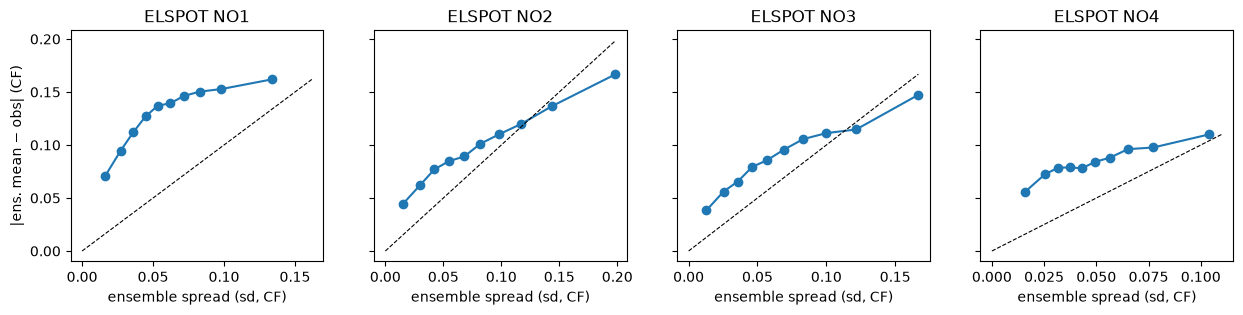

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3), sharey=True)
for ax, zone in zip(axes, ZONES):
    g = d.loc[(d["zone"] == zone) & (d["fold"] == "train")]
    bins = pd.qcut(g["spread"], 10)
    b = g.groupby(bins, observed=True).agg(spread=("spread", "mean"), abs_err=("abs_err", "mean"))
    ax.plot(b["spread"], b["abs_err"], "o-")
    lim = max(b["spread"].max(), b["abs_err"].max())
    ax.plot([0, lim], [0, lim], "k--", lw=0.8)
    ax.set_title(zone); ax.set_xlabel("ensemble spread (sd, CF)")
axes[0].set_ylabel("|ens. mean − obs| (CF)")
plt.show()

### Findings (4)
- **Bias is small:** |mean bias| ≤ 0.05 CF. The largest is NO4 val at −0.049 (underpredicts) and NO3 val at
  +0.026.
- **The ensemble is strongly under-dispersive.** The observation lies within the members' range only
  41–64 % of the time. For 15 exchangeable members it should be 14/16 = 87.5 %. NO1 is worst (41 %).
- **The spread does carry information.** The error grows with the spread in every zone (correlation 0.20–0.40
  on train), but at low spread the error is far larger than the spread. In NO2 and NO3 the two meet only at the
  highest spreads.
- **Consequence:** the raw ensemble needs calibration. That's EMOS's job: its variance term
  (c + d · spread²) can inflate the spread, and its mean term can remove the bias.

## Summary
| Check | Result |
|---|---|
| Curve fit | Follows the data, including the high-wind drop via the cut-out factor (NO2–NO4). NO1 has no high-wind data, so no cut-out. |
| Alignment weights | Centre 0.24–0.45 h after t, same direction as C9, but mixed with smoothing. C9 stays open. |
| Member-00 RMSE | NO3 230 / 254 MW (train / val) vs ~280 MW in the paper: plausible. |
| Ensemble | Small bias, strongly under-dispersive (41–64 % inside the range vs 87.5 %), spread informative. |

The test fold is not looked at in this notebook (touched once).